In [1]:
%pip install -q kagglehub

In [2]:
import os
import struct
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [3]:
import kagglehub

path = kagglehub.dataset_download("hojjatk/mnist-dataset")
ROOT = Path(path)

print("Путь к датасету:", ROOT)

for dirpath, dirnames, filenames in os.walk(ROOT):
    depth = Path(dirpath).relative_to(ROOT).parts
    if len(depth) <= 2:
        print(f"{'  ' * len(depth)}{Path(dirpath).name}/")
        for filename in filenames[:5]:
            print(f"{'  ' * (len(depth) + 1)}{filename}")

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Путь к датасету: /kaggle/input/mnist-dataset
mnist-dataset/
  train-images.idx3-ubyte
  t10k-labels.idx1-ubyte
  t10k-images.idx3-ubyte
  train-labels.idx1-ubyte
  t10k-labels-idx1-ubyte/
    t10k-labels-idx1-ubyte
  t10k-images-idx3-ubyte/
    t10k-images-idx3-ubyte
  train-labels-idx1-ubyte/
    train-labels-idx1-ubyte
  train-images-idx3-ubyte/
    train-images-idx3-ubyte


In [8]:
from pathlib import Path

def find_file(root, *candidates):
    """Ищет именно файл, а не папку."""
    root = Path(root)

    for name in candidates:
        # Проверяем совпадения во всех вложенных папках
        for path in root.rglob(name):
            if path.is_file():
                return path

    raise FileNotFoundError(
        f"Не найден файл из списка {candidates} в {root}"
    )

In [9]:
train_images_path = find_file(
    ROOT, "train-images-idx3-ubyte", "train-images.idx3-ubyte"
)
train_labels_path = find_file(
    ROOT, "train-labels-idx1-ubyte", "train-labels.idx1-ubyte"
)
test_images_path = find_file(
    ROOT, "t10k-images-idx3-ubyte", "t10k-images.idx3-ubyte"
)
test_labels_path = find_file(
    ROOT, "t10k-labels-idx1-ubyte", "t10k-labels.idx1-ubyte"
)

X_train_full = read_idx_images(train_images_path)
y_train_full = read_idx_labels(train_labels_path)
X_test = read_idx_images(test_images_path)
y_test = read_idx_labels(test_labels_path)

# Выделяем 10% обучающей выборки для валидации
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.1,
    random_state=SEED,
    stratify=y_train_full
)

# Для нейросети удобнее значения пикселей в диапазоне [0, 1]
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print(f"Train:      X={X_train.shape}, y={y_train.shape}")
print(f"Validation: X={X_val.shape}, y={y_val.shape}")
print(f"Test:       X={X_test.shape}, y={y_test.shape}")

Train:      X=(54000, 28, 28), y=(54000,)
Validation: X=(6000, 28, 28), y=(6000,)
Test:       X=(10000, 28, 28), y=(10000,)


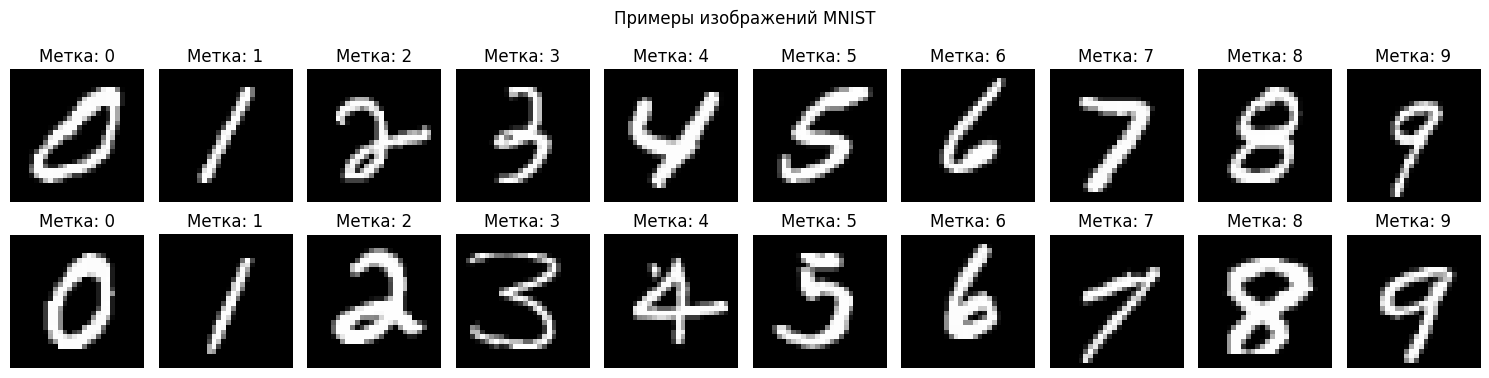

Количество примеров каждого класса в train:
Цифра 0: 5331
Цифра 1: 6068
Цифра 2: 5362
Цифра 3: 5518
Цифра 4: 5258
Цифра 5: 4879
Цифра 6: 5326
Цифра 7: 5638
Цифра 8: 5266
Цифра 9: 5354


In [10]:
fig, axes = plt.subplots(2, 10, figsize=(15, 4))
for digit in range(10):
    indices = np.where(y_train == digit)[0][:2]
    for row, idx in enumerate(indices):
        axes[row, digit].imshow(X_train[idx], cmap="gray")
        axes[row, digit].set_title(f"Метка: {y_train[idx]}")
        axes[row, digit].axis("off")

plt.suptitle("Примеры изображений MNIST")
plt.tight_layout()
plt.show()

print("Количество примеров каждого класса в train:")
for digit, count in zip(*np.unique(y_train, return_counts=True)):
    print(f"Цифра {digit}: {count}")

In [11]:
# CNN принимает изображения в формате (высота, ширина, каналы)
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, kernel_size=3, activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Conv2D(64, kernel_size=3, activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=4,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/4
422/422 ━━━━━━━━━━━━━━━━━━━━ 37s 87ms/step - accuracy: 0.9810 - loss: 0.0614 - val_accuracy: 0.9850 - val_loss: 0.0526
Epoch 2/4
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.9859 - loss: 0.0473 - val_accuracy: 0.9887 - val_loss: 0.0428
Epoch 3/4
422/422 ━━━━━━━━━━━━━━━━━━━━ 71s 86ms/step - accuracy: 0.9880 - loss: 0.0379 - val_accuracy: 0.9852 - val_loss: 0.0528
Epoch 4/4
422/422 ━━━━━━━━━━━━━━━━━━━━ 36s 85ms/step - accuracy: 0.9902 - loss: 0.0312 - val_accuracy: 0.9875 - val_loss: 0.0437


##  Графики обучения

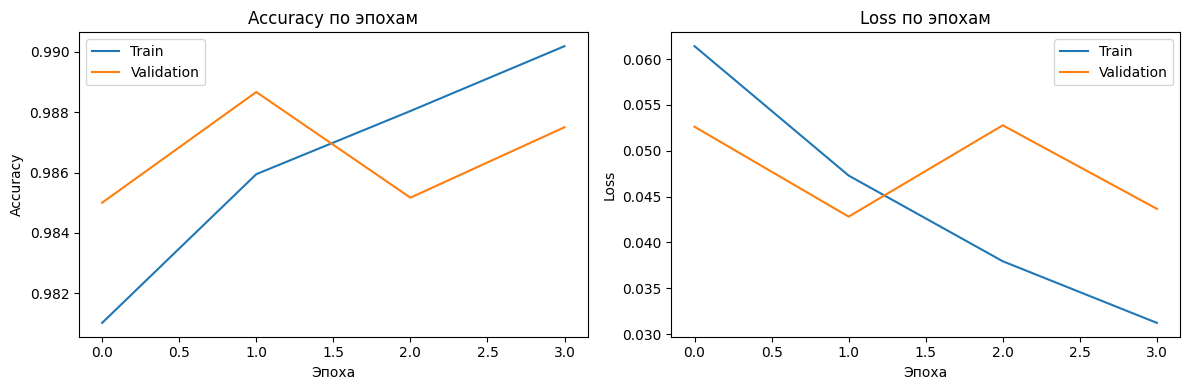

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy по эпохам")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss по эпохам")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## Оценка на тестовой выборке

In [15]:
test_loss, test_accuracy = model.evaluate(X_test_cnn, y_test, verbose=0)
y_prob = model.predict(X_test_cnn, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print()
print(classification_report(y_test, y_pred, digits=4))

Test loss: 0.0284
Test accuracy: 0.9896

              precision    recall  f1-score   support

           0     0.9908    0.9939    0.9924       980
           1     0.9938    0.9965    0.9952      1135
           2     0.9913    0.9884    0.9898      1032
           3     0.9930    0.9881    0.9906      1010
           4     0.9929    0.9949    0.9939       982
           5     0.9801    0.9922    0.9861       892
           6     0.9927    0.9906    0.9916       958
           7     0.9797    0.9874    0.9835      1028
           8     0.9897    0.9867    0.9882       974
           9     0.9910    0.9772    0.9840      1009

    accuracy                         0.9896     10000
   macro avg     0.9895    0.9896    0.9895     10000
weighted avg     0.9896    0.9896    0.9896     10000



## Матрица ошибок

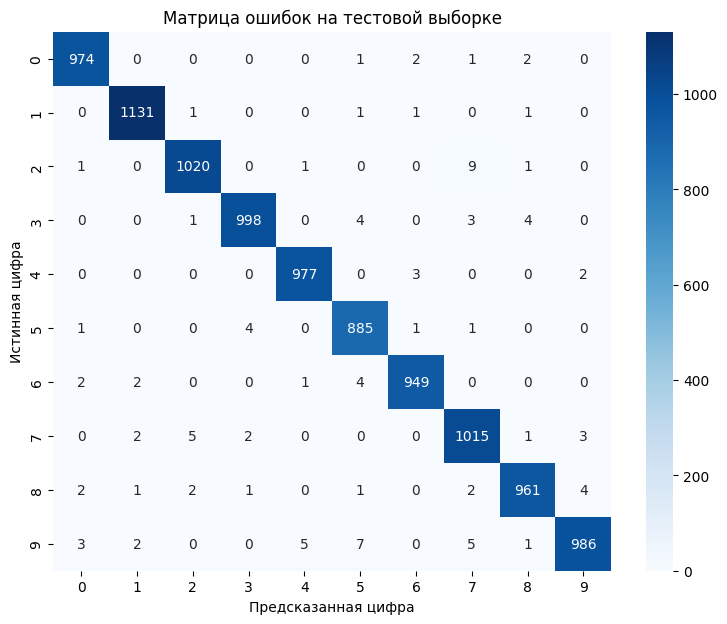

In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Предсказанная цифра")
plt.ylabel("Истинная цифра")
plt.title("Матрица ошибок на тестовой выборке")
plt.show()

## Примеры правильных и неправильных предсказаний

Ошибочных предсказаний: 104 из 10000


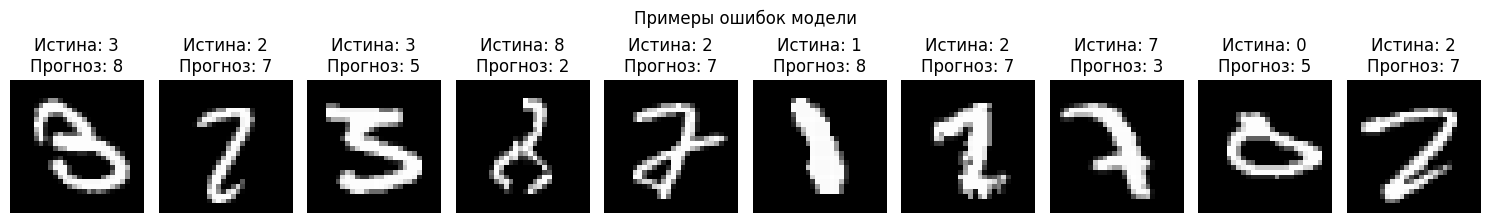

In [17]:
wrong_indices = np.where(y_pred != y_test)[0]
correct_indices = np.where(y_pred == y_test)[0]

print("Ошибочных предсказаний:", len(wrong_indices), "из", len(y_test))

# Сначала покажем до 10 ошибок, если они есть
indices_to_show = wrong_indices[:10] if len(wrong_indices) else correct_indices[:10]

fig, axes = plt.subplots(1, min(10, len(indices_to_show)), figsize=(15, 2.5))
if len(indices_to_show) == 1:
    axes = [axes]

for ax, idx in zip(axes, indices_to_show):
    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(f"Истина: {y_test[idx]}\nПрогноз: {y_pred[idx]}")
    ax.axis("off")

plt.suptitle("Примеры ошибок модели" if len(wrong_indices) else "Примеры верных прогнозов")
plt.tight_layout()
plt.show()

##Вывод

После запуска ячеек заполните вывод фактическими результатами эксперимента:

- Размер обучающей выборки: **укажите значение из вывода ячейки 4**.
- Размер тестовой выборки: **укажите значение из вывода ячейки 4**.
- Точность на тестовой выборке: **укажите значение `Test accuracy` из ячейки 8**.
- Матрица ошибок показывает, какие цифры модель чаще всего путает.
- CNN использует свёрточные слои, которые помогают находить локальные признаки изображения, а слой `softmax` выдаёт вероятности для 10 классов (цифр от 0 до 9).

Не вписывайте предполагаемую точность заранее — используйте результат собственного запуска.